In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from scipy.stats import chi2_contingency

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore', category=FutureWarning)
RANDOM_STATE = 42
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.width', 140)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.titleweight'] = 'bold'

print('Libraries loaded. Random state:', RANDOM_STATE)

Libraries loaded. Random state: 42


## 2. Load the raw dataset

In [2]:
DATA_PATH = Path('train.csv')

if not DATA_PATH.exists():
    # Google Colab upload fallback. In local Jupyter, place train.csv beside this notebook.
    try:
        from google.colab import files
        print('Please upload the original train.csv file.')
        uploaded = files.upload()
        candidates = [name for name in uploaded if name.lower().endswith('.csv')]
        if not candidates:
            raise FileNotFoundError('No CSV file was uploaded.')
        DATA_PATH = Path(candidates[0])
    except ImportError as exc:
        raise FileNotFoundError(
            'Could not find train.csv. Put it in the notebook folder or upload it in Colab.'
        ) from exc

raw_df = pd.read_csv(DATA_PATH)
df = raw_df.copy()
print(f'Loaded: {DATA_PATH.resolve()}')
print(f'Shape: {df.shape[0]:,} rows x {df.shape[1]} columns')
display(df.head(10))

Loaded: /mnt/data/train.csv
Shape: 891 rows x 12 columns


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


## 3. Dataset overview and schema

In [3]:
profile = pd.DataFrame({
    'Data type': df.dtypes.astype(str),
    'Non-missing': df.notna().sum(),
    'Missing': df.isna().sum(),
    'Missing %': (df.isna().mean() * 100).round(2),
    'Unique non-missing': df.nunique(dropna=True)
}).sort_values('Missing', ascending=False)

display(profile)
print(f"\nDuplicate rows: {df.duplicated().sum()}")
print(f"Total missing cells: {int(df.isna().sum().sum())}")

,Data type,Non-missing,Missing,Missing %,Unique non-missing
Cabin,object,204,687,77.10,147
Age,float64,714,177,19.87,88
Embarked,object,889,2,0.22,3
PassengerId,int64,891,0,0.00,891
Name,object,891,0,0.00,891
Pclass,int64,891,0,0.00,3
Survived,int64,891,0,0.00,2
Sex,object,891,0,0.00,2
Parch,int64,891,0,0.00,7
SibSp,int64,891,0,0.00,7



Duplicate rows: 0
Total missing cells: 866


## 4. Missing-value audit

,Missing,Missing %,Non-missing
Cabin,687,77.10,204
Age,177,19.87,714
Embarked,2,0.22,889


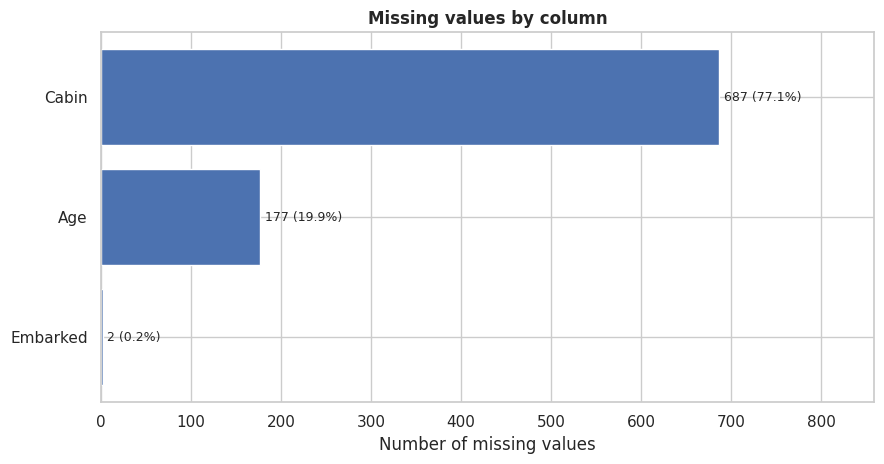

In [4]:
missing = df.isna().sum().rename('Missing').to_frame()
missing['Missing %'] = (missing['Missing'] / len(df) * 100).round(2)
missing['Non-missing'] = df.notna().sum()
missing = missing.sort_values('Missing', ascending=False)
display(missing[missing['Missing'] > 0])

fig, ax = plt.subplots(figsize=(9, 4.8))
plot_missing = missing[missing['Missing'] > 0].sort_values('Missing')
if len(plot_missing):
    bars = ax.barh(plot_missing.index, plot_missing['Missing'])
    ax.set_title('Missing values by column')
    ax.set_xlabel('Number of missing values')
    for bar, pct in zip(bars, plot_missing['Missing %']):
        ax.text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2,
                f'{int(bar.get_width())} ({pct:.1f}%)', va='center', fontsize=9)
    ax.set_xlim(0, max(plot_missing['Missing']) * 1.25)
else:
    ax.text(0.5, 0.5, 'No missing values found', ha='center', va='center')
plt.tight_layout()
plt.show()

## 5. Descriptive statistics

In [5]:
print('Numeric columns - descriptive statistics')
display(df.describe().T.round(3))

print('All columns - include categorical attributes')
display(df.describe(include='all').T)

Numeric columns - descriptive statistics


,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000,257.354,1.00,223.500,446.000,668.5,891.000
Survived,891.0,0.384,0.487,0.00,0.000,0.000,1.0,1.000
Pclass,891.0,2.309,0.836,1.00,2.000,3.000,3.0,3.000
Age,714.0,29.699,14.526,0.42,20.125,28.000,38.0,80.000
SibSp,891.0,0.523,1.103,0.00,0.000,0.000,1.0,8.000
Parch,891.0,0.382,0.806,0.00,0.000,0.000,0.0,6.000
Fare,891.0,32.204,49.693,0.00,7.910,14.454,31.0,512.329


All columns - include categorical attributes


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,1601,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


## 6. Attribute counts and frequent values

In [6]:
for col in ['Survived', 'Pclass', 'Sex', 'Embarked', 'SibSp', 'Parch']:
    print(f'\n--- {col} ---')
    display(df[col].value_counts(dropna=False).rename_axis('Value').to_frame('Count'))

print('\nMost common Ticket values')
display(df['Ticket'].value_counts().head(10).rename_axis('Ticket').to_frame('Count'))
print('\nMost common non-missing Cabin values')
display(df['Cabin'].value_counts().head(10).rename_axis('Cabin').to_frame('Count'))


--- Survived ---


,Count
Value,
0,549
1,342



--- Pclass ---


,Count
Value,
3,491
1,216
2,184



--- Sex ---


...

,Count
Value,
0,678
1,118
2,80
5,5
3,5
4,4
6,1



Most common Ticket values


,Count
Ticket,
1601,7
CA. 2343,7
347082,7
3101295,6
CA 2144,6
347088,6
382652,5
S.O.C. 14879,5
17421,4



Most common non-missing Cabin values


,Count
Cabin,
G6,4
C23 C25 C27,4
B96 B98,4
F2,3
D,3
E101,3
C22 C26,3
F33,3
C83,2


## 7. Feature engineering

We extract a passenger title from `Name`, group uncommon titles into `Rare`, and derive family features. These transformations use the values of a row and do not use `Survived` as an input.

- `Title`: text between the comma after the surname and the period after the title.
- `FamilySize`: `SibSp + Parch + 1`.
- `IsAlone`: 1 when `FamilySize == 1`, else 0.
- `HasCabin`: 1 when a cabin value exists, else 0.

For model evaluation, imputation and one-hot encoding are fitted inside scikit-learn pipelines on each training fold. The fully imputed CSV is an exploratory/export artifact; use the pipelines for honest evaluation.

In [7]:
df['Title'] = df['Name'].str.extract(r',\s*([^\.]+)\.', expand=False)
# Normalize uncommon variants that map naturally to common titles.
df['Title'] = df['Title'].replace({
    'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs', 'the Countess': 'Countess'
})
rare_titles = [
    'Dr', 'Rev', 'Col', 'Major', 'Countess', 'Capt', 'Sir',
    'Lady', 'Jonkheer', 'Don', 'Dona'
]
df['Title'] = df['Title'].replace(rare_titles, 'Rare')
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['IsAlone'] = (df['FamilySize'] == 1).astype(int)
df['HasCabin'] = df['Cabin'].notna().astype(int)

display(df[['Name', 'Title', 'SibSp', 'Parch', 'FamilySize', 'IsAlone', 'Cabin', 'HasCabin']].head(12))
print('Title counts:')
display(df['Title'].value_counts(dropna=False).rename_axis('Title').to_frame('Passengers'))

,Name,Title,SibSp,Parch,FamilySize,IsAlone,Cabin,HasCabin
0,"Braund, Mr. Owen Harris",Mr,1,0,2,0,NaN,0
1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",Mrs,1,0,2,0,C85,1
2,"Heikkinen, Miss. Laina",Miss,0,0,1,1,NaN,0
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,1,0,2,0,C123,1
4,"Allen, Mr. William Henry",Mr,0,0,1,1,NaN,0
5,"Moran, Mr. James",Mr,0,0,1,1,NaN,0
6,"McCarthy, Mr. Timothy J",Mr,0,0,1,1,E46,1
7,"Palsson, Master. Gosta Leonard",Master,3,1,5,0,NaN,0
8,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",Mrs,0,2,3,0,NaN,0
9,"Nasser, Mrs. Nicholas (Adele Achem)",Mrs,1,0,2,0,NaN,0


Title counts:


,Passengers
Title,
Mr,517
Miss,185
Mrs,126
Master,40
Rare,23


## 8. Target balance

,Count,Percent
Survived,,
Did not survive (0),549,61.62
Survived (1),342,38.38


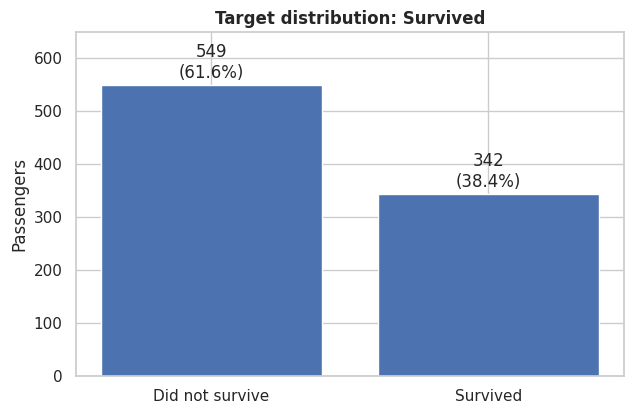

In [8]:
target_counts = df['Survived'].value_counts().sort_index()
target_share = (target_counts / len(df) * 100).round(2)
target_summary = pd.DataFrame({'Count': target_counts, 'Percent': target_share})
target_summary.index = target_summary.index.map({0: 'Did not survive (0)', 1: 'Survived (1)'})
display(target_summary)

fig, ax = plt.subplots(figsize=(6.5, 4.3))
labels = ['Did not survive', 'Survived']
counts = [int(target_counts.get(0, 0)), int(target_counts.get(1, 0))]
bars = ax.bar(labels, counts)
ax.set_title('Target distribution: Survived')
ax.set_ylabel('Passengers')
for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 6,
            f'{count}\n({count/len(df):.1%})', ha='center', va='bottom')
ax.set_ylim(0, max(counts) * 1.18)
plt.tight_layout()
plt.show()

## 9. Univariate visual exploration

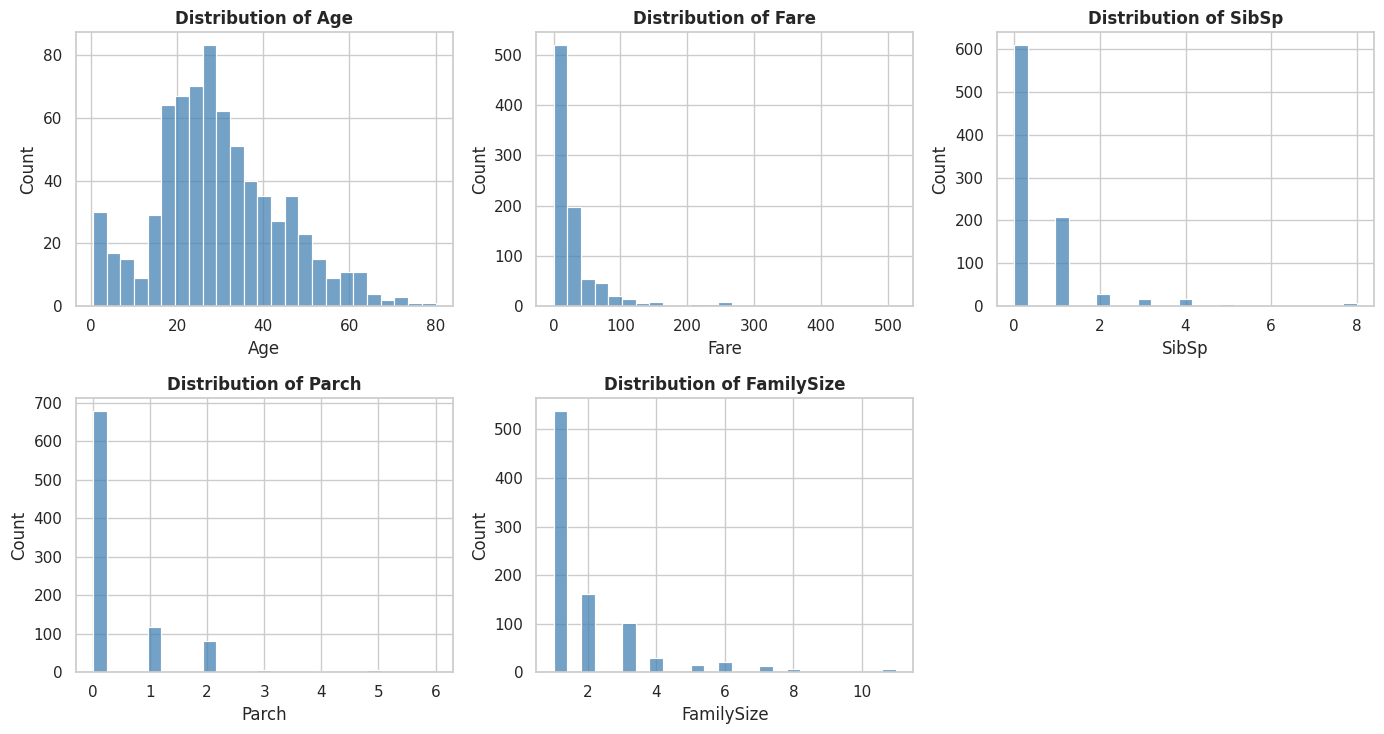

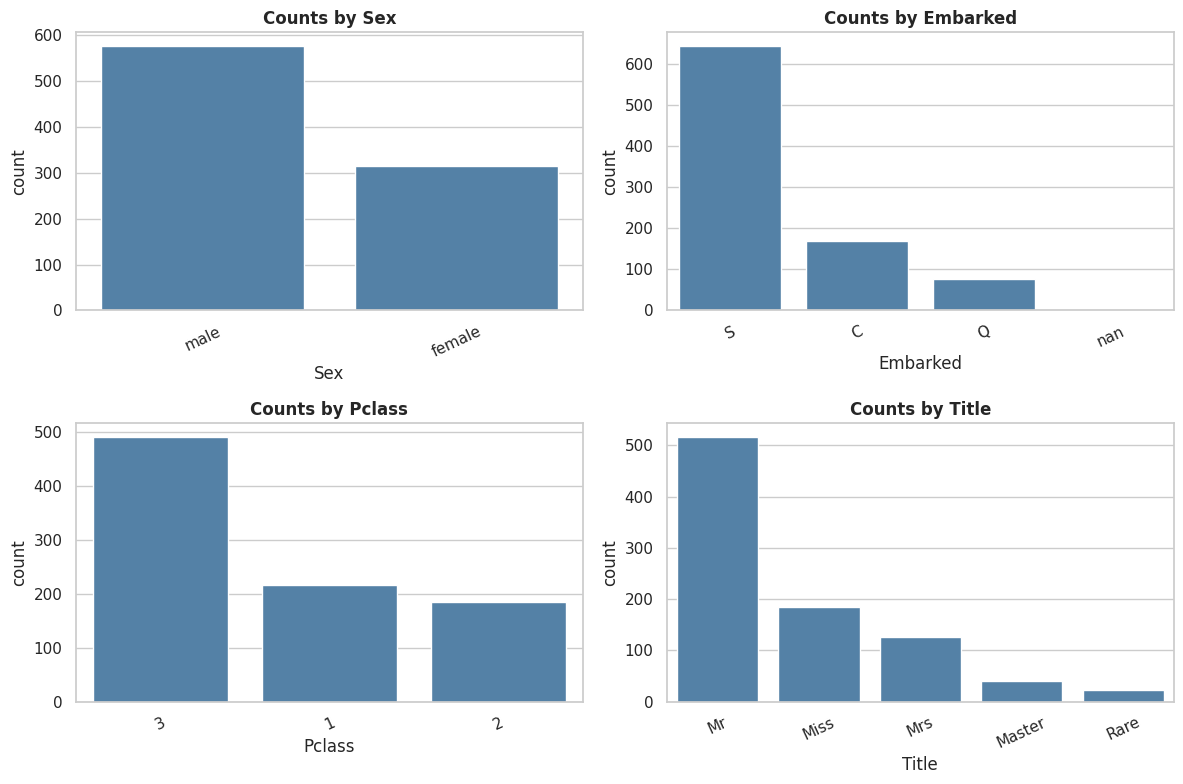

In [9]:
num_plot_cols = ['Age', 'Fare', 'SibSp', 'Parch', 'FamilySize']
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, col in zip(axes.flat, num_plot_cols):
    sns.histplot(data=df, x=col, bins=25, kde=False, color='steelblue', ax=ax)
    ax.set_title(f'Distribution of {col}')
for ax in axes.flat[len(num_plot_cols):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, ['Sex', 'Embarked', 'Pclass', 'Title']):
    order = df[col].value_counts(dropna=False).index
    sns.countplot(data=df, x=col, order=order, color='steelblue', ax=ax)
    ax.set_title(f'Counts by {col}')
    ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

## 10. Survival rates by group


Survival by Sex


,Passengers,Survival_Rate
Sex,,
male,577,18.89
female,314,74.20



Survival by Pclass


,Passengers,Survival_Rate
Pclass,,
3,491,24.24
1,216,62.96
2,184,47.28



Survival by Embarked


,Passengers,Survival_Rate
Embarked,,
S,644,33.70
C,168,55.36
Q,77,38.96
NaN,2,100.00



Survival by Title


,Passengers,Survival_Rate
Title,,
Mr,517,15.67
Miss,185,70.27
Mrs,126,79.37
Master,40,57.50
Rare,23,34.78


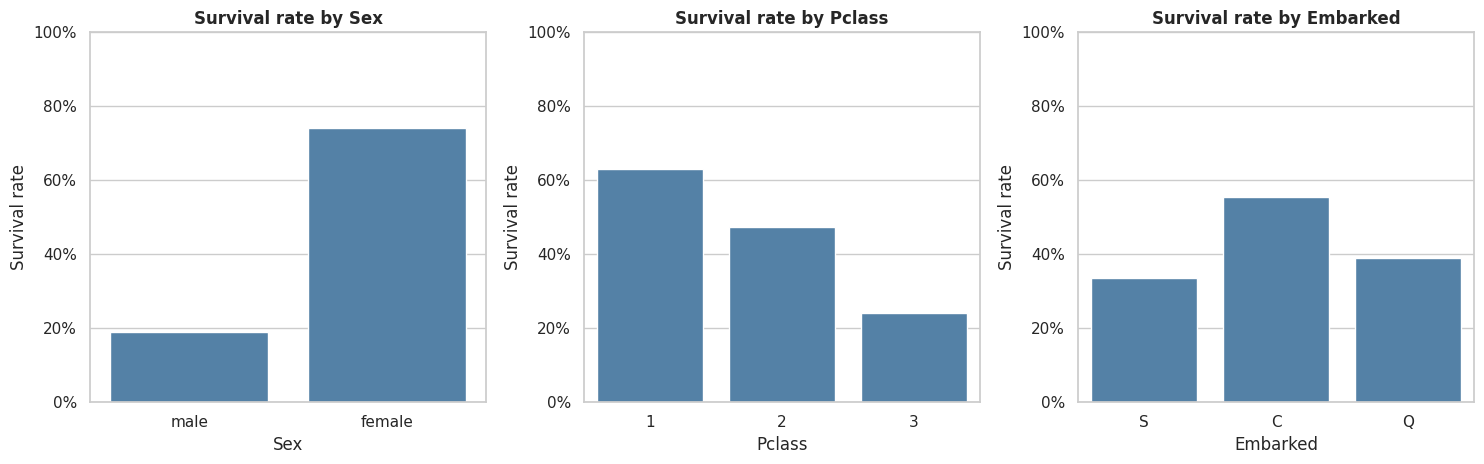

In [10]:
for col in ['Sex', 'Pclass', 'Embarked', 'Title']:
    print(f'\nSurvival by {col}')
    summary = df.groupby(col, dropna=False)['Survived'].agg(Passengers='size', Survival_Rate='mean')
    summary['Survival_Rate'] = (summary['Survival_Rate'] * 100).round(2)
    display(summary.sort_values('Passengers', ascending=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, col in zip(axes, ['Sex', 'Pclass', 'Embarked']):
    sns.barplot(data=df, x=col, y='Survived', errorbar=None, color='steelblue', ax=ax)
    ax.set_title(f'Survival rate by {col}')
    ax.set_ylabel('Survival rate')
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
plt.tight_layout()
plt.show()

## 11. Age, fare, and family-size patterns

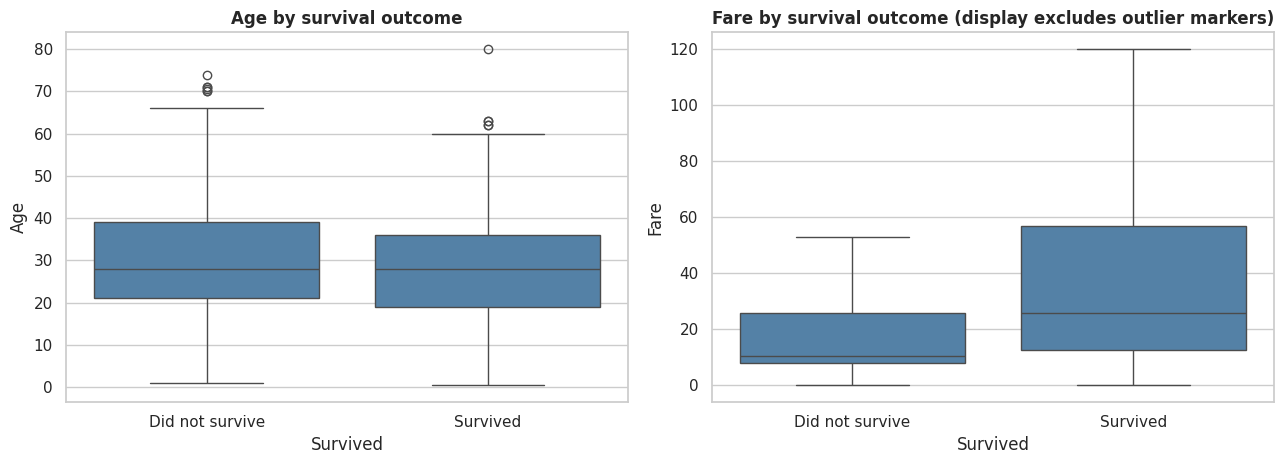

,Passengers,Survival_Rate
FamilySize,,
1,537,30.35
2,161,55.28
3,102,57.84
4,29,72.41
5,15,20.00
6,22,13.64
7,12,33.33


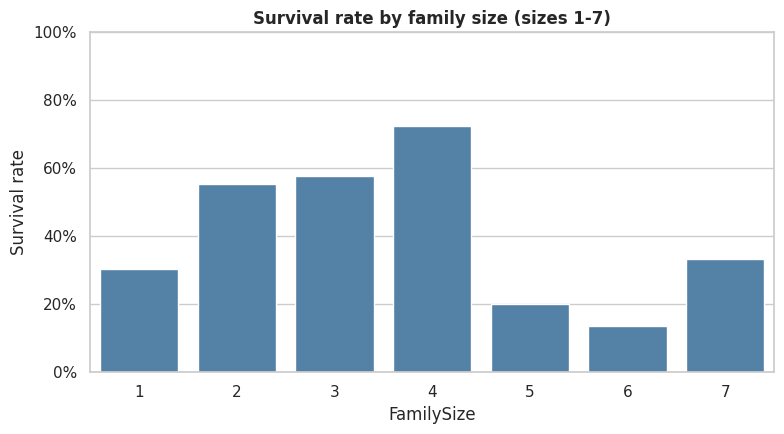

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.boxplot(data=df, x='Survived', y='Age', color='steelblue', ax=axes[0])
axes[0].set_title('Age by survival outcome')
axes[0].set_xticks([0, 1], ['Did not survive', 'Survived'])
sns.boxplot(data=df, x='Survived', y='Fare', showfliers=False, color='steelblue', ax=axes[1])
axes[1].set_title('Fare by survival outcome (display excludes outlier markers)')
axes[1].set_xticks([0, 1], ['Did not survive', 'Survived'])
plt.tight_layout()
plt.show()

family_rates = df[df['FamilySize'].between(1, 7)].groupby('FamilySize')['Survived'].agg(
    Passengers='size', Survival_Rate='mean'
)
family_rates['Survival_Rate'] *= 100
display(family_rates.round(2))
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=df[df['FamilySize'].between(1, 7)], x='FamilySize', y='Survived',
            errorbar=None, color='steelblue', ax=ax)
ax.set_title('Survival rate by family size (sizes 1-7)')
ax.set_ylabel('Survival rate')
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
plt.tight_layout()
plt.show()

## 12. Correlation matrices

Pearson summarizes linear correlation; Spearman summarizes rank correlation. With a binary outcome, these coefficients describe association and do not establish causality.

Pearson correlation matrix


,Survived,Pclass,Age,SibSp,Parch,Fare,FamilySize,IsAlone,HasCabin
Survived,1.000,-0.338,-0.077,-0.035,0.082,0.257,0.017,-0.203,0.317
Pclass,-0.338,1.000,-0.369,0.083,0.018,-0.549,0.066,0.135,-0.726
Age,-0.077,-0.369,1.000,-0.308,-0.189,0.096,-0.302,0.198,0.250
SibSp,-0.035,0.083,-0.308,1.000,0.415,0.160,0.891,-0.584,-0.040
Parch,0.082,0.018,-0.189,0.415,1.000,0.216,0.783,-0.583,0.037
Fare,0.257,-0.549,0.096,0.160,0.216,1.000,0.217,-0.272,0.482
FamilySize,0.017,0.066,-0.302,0.891,0.783,0.217,1.000,-0.691,-0.009
IsAlone,-0.203,0.135,0.198,-0.584,-0.583,-0.272,-0.691,1.000,-0.158
HasCabin,0.317,-0.726,0.250,-0.040,0.037,0.482,-0.009,-0.158,1.000


Spearman correlation matrix


,Survived,Pclass,Age,SibSp,Parch,Fare,FamilySize,IsAlone,HasCabin
Survived,1.000,-0.340,-0.053,0.089,0.138,0.324,0.165,-0.203,0.317
Pclass,-0.340,1.000,-0.362,-0.043,-0.023,-0.688,-0.076,0.136,-0.683
Age,-0.053,-0.362,1.000,-0.182,-0.254,0.135,-0.228,0.167,0.247
SibSp,0.089,-0.043,-0.182,1.000,0.450,0.447,0.849,-0.828,0.052
Parch,0.138,-0.023,-0.254,0.450,1.000,0.410,0.801,-0.684,0.080
Fare,0.324,-0.688,0.135,0.447,0.410,1.000,0.529,-0.531,0.539
FamilySize,0.165,-0.076,-0.228,0.849,0.801,0.529,1.000,-0.964,0.109
IsAlone,-0.203,0.136,0.167,-0.828,-0.684,-0.531,-0.964,1.000,-0.158
HasCabin,0.317,-0.683,0.247,0.052,0.080,0.539,0.109,-0.158,1.000


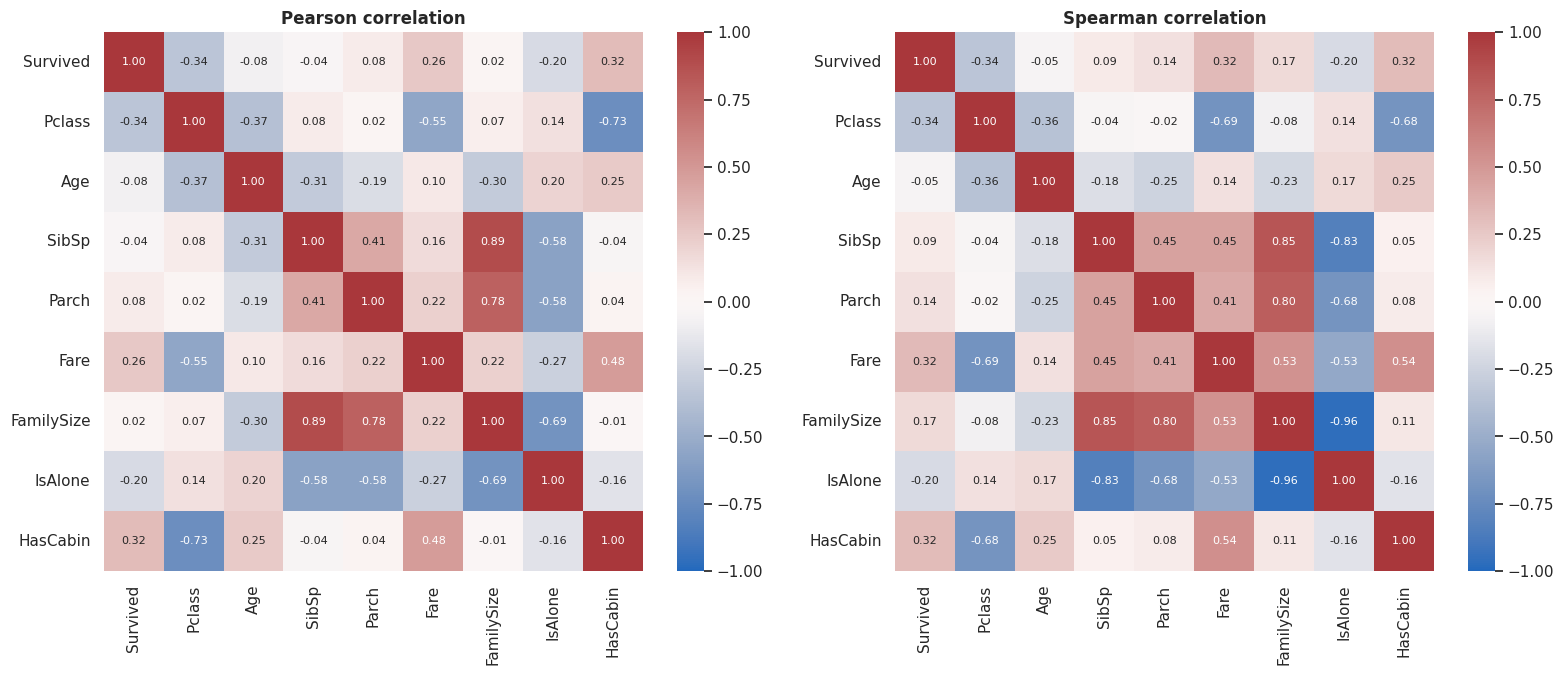

,Pearson with Survived,Spearman with Survived
Pclass,-0.338,-0.340
IsAlone,-0.203,-0.203
Age,-0.077,-0.053
SibSp,-0.035,0.089
FamilySize,0.017,0.165
Parch,0.082,0.138
Fare,0.257,0.324
HasCabin,0.317,0.317


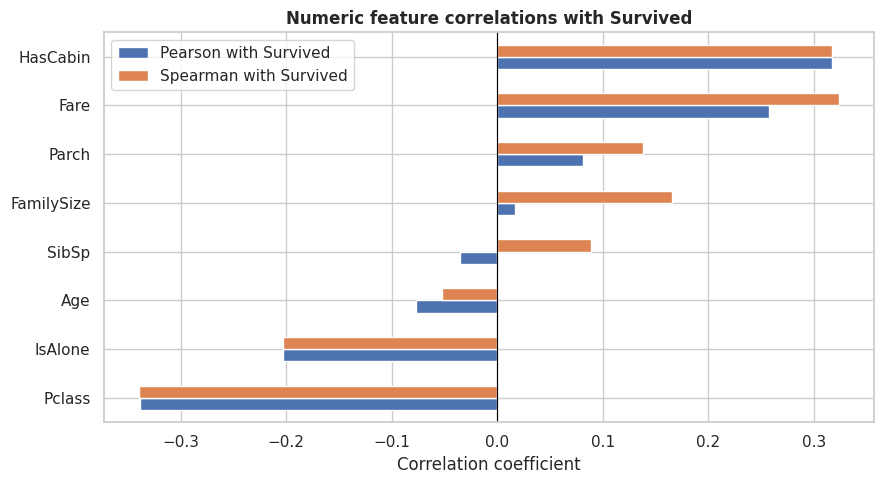

In [12]:
correlation_cols = ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare',
                    'FamilySize', 'IsAlone', 'HasCabin']
pearson_corr = df[correlation_cols].corr(method='pearson')
spearman_corr = df[correlation_cols].corr(method='spearman')

print('Pearson correlation matrix')
display(pearson_corr.round(3))
print('Spearman correlation matrix')
display(spearman_corr.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
sns.heatmap(pearson_corr, annot=True, fmt='.2f', cmap='vlag', center=0,
            vmin=-1, vmax=1, square=True, ax=axes[0], annot_kws={'size': 8})
axes[0].set_title('Pearson correlation')
sns.heatmap(spearman_corr, annot=True, fmt='.2f', cmap='vlag', center=0,
            vmin=-1, vmax=1, square=True, ax=axes[1], annot_kws={'size': 8})
axes[1].set_title('Spearman correlation')
plt.tight_layout()
plt.show()

corr_target = pd.DataFrame({
    'Pearson with Survived': pearson_corr['Survived'].drop('Survived'),
    'Spearman with Survived': spearman_corr['Survived'].drop('Survived')
}).sort_values('Pearson with Survived')
display(corr_target.round(3))
ax = corr_target.plot(kind='barh', figsize=(9, 5), title='Numeric feature correlations with Survived')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Correlation coefficient')
plt.tight_layout()
plt.show()

## 13. Categorical association with the target (Cramér's V)

Cramér’s V is a normalized association measure derived from a chi-square contingency table. It ranges from 0 to 1; higher values indicate stronger association for the table being evaluated.

,Feature,Cramer's V with Survived
0,Title,0.565
1,Sex,0.543
2,Pclass,0.337
3,HasCabin,0.315
4,IsAlone,0.201
5,Embarked,0.173


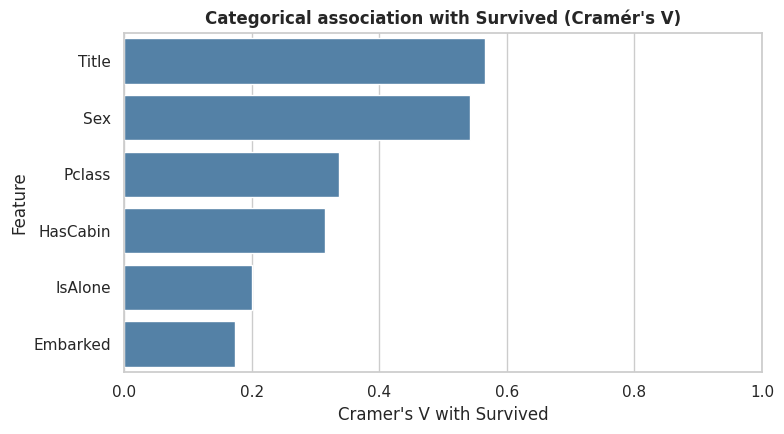

In [13]:
def cramers_v(x, y):
    table = pd.crosstab(x, y, dropna=False)
    if table.shape[0] < 2 or table.shape[1] < 2:
        return np.nan
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    phi2 = chi2 / n
    r, k = table.shape
    # Bias-corrected Cramer's V
    phi2corr = max(0, phi2 - ((k - 1) * (r - 1)) / max(n - 1, 1))
    rcorr = r - ((r - 1) ** 2) / max(n - 1, 1)
    kcorr = k - ((k - 1) ** 2) / max(n - 1, 1)
    denom = min(kcorr - 1, rcorr - 1)
    return np.sqrt(phi2corr / denom) if denom > 0 else np.nan

association_features = ['Title', 'Sex', 'Pclass', 'HasCabin', 'IsAlone', 'Embarked']
association = pd.DataFrame({
    'Feature': association_features,
    "Cramer's V with Survived": [cramers_v(df[col].fillna('Missing'), df['Survived'])
                                  for col in association_features]
}).sort_values("Cramer's V with Survived", ascending=False)
display(association.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=association, x="Cramer's V with Survived", y='Feature', color='steelblue', ax=ax)
ax.set_xlim(0, 1)
ax.set_title("Categorical association with Survived (Cramér's V)")
plt.tight_layout()
plt.show()

## 14. Prepare features and train/test split

The split is **80% training / 20% testing**, stratified by `Survived`, with `random_state=42`. That produces 712 training rows and 179 held-out test rows. `PassengerId`, raw `Name`, raw `Ticket`, and raw `Cabin` are not used directly in the models. `Title` and `HasCabin` retain useful information from `Name` and `Cabin` respectively.

In [14]:
TARGET = 'Survived'
FEATURES = [
    'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked',
    'Title', 'FamilySize', 'IsAlone', 'HasCabin'
]
NUMERIC_FEATURES = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone', 'HasCabin']
CATEGORICAL_FEATURES = ['Sex', 'Embarked', 'Title']

X = df[FEATURES].copy()
y = df[TARGET].astype(int).copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print('Training target proportions:')
display(y_train.value_counts(normalize=True).sort_index().rename('Proportion').to_frame())
print('Test target proportions:')
display(y_test.value_counts(normalize=True).sort_index().rename('Proportion').to_frame())

X_train: (712, 11) | X_test: (179, 11)
Training target proportions:


,Proportion
Survived,
0,0.616573
1,0.383427


Test target proportions:


,Proportion
Survived,
0,0.614525
1,0.385475


## 15. Preprocessing pipeline and classifiers

Numeric columns use **mean imputation** and standardization. Categorical columns use **most-frequent imputation** and one-hot encoding. These transformations are inside the estimator pipeline, so cross-validation learns imputation/encoding from each training fold rather than from the validation fold.

In [15]:
numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer(transformers=[
    ('numeric', numeric_pipeline, NUMERIC_FEATURES),
    ('categorical', categorical_pipeline, CATEGORICAL_FEATURES)
])

models = {
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    'AdaBoost': AdaBoostClassifier(n_estimators=100, random_state=RANDOM_STATE),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=7),
    'Gaussian Naive Bayes': GaussianNB(),
    'Shallow Decision Tree': DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    'Dummy Majority Baseline': DummyClassifier(strategy='most_frequent')
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print(f'{len(models)} models configured; 5-fold stratified CV is restricted to training data.')

7 models configured; 5-fold stratified CV is restricted to training data.


## 16. Cross-validation and held-out test results

Model,CV accuracy mean,CV accuracy std,Test accuracy,Balanced accuracy,Precision (survived),Recall (survived),F1 (survived),ROC-AUC
Logistic Regression,0.8245,0.0317,0.8324,0.8177,0.8000,0.7536,0.7761,0.8722
Shallow Decision Tree,0.8076,0.0189,0.8156,0.8014,0.7727,0.7391,0.7556,0.8388
Gaussian Naive Bayes,0.8076,0.0333,0.8156,0.8095,0.7500,0.7826,0.7660,0.8515
AdaBoost,0.8202,0.0261,0.8101,0.8130,0.7215,0.8261,0.7703,0.8363
Random Forest,0.8189,0.0215,0.8045,0.7923,0.7500,0.7391,0.7445,0.8274
K-Nearest Neighbors,0.8090,0.0255,0.7933,0.7778,0.7424,0.7101,0.7259,0.8613
Dummy Majority Baseline,0.6166,0.0031,0.6145,0.5000,0.0000,0.0000,0.0000,0.5000


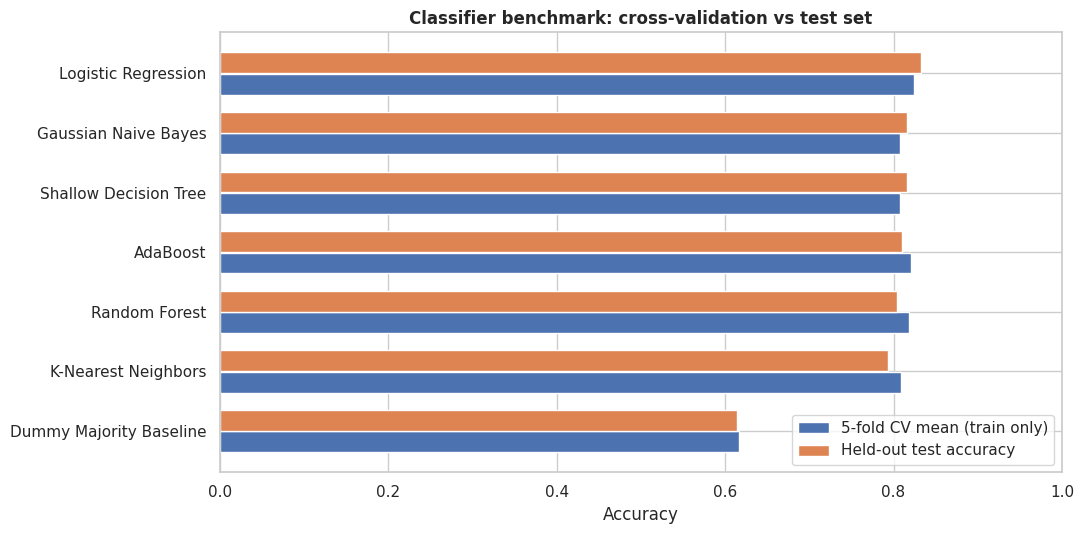

In [16]:
results = []
fitted_models = {}

for model_name, estimator in models.items():
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', estimator)])
    cv_scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    if hasattr(pipeline, 'predict_proba'):
        y_score = pipeline.predict_proba(X_test)[:, 1]
    elif hasattr(pipeline, 'decision_function'):
        y_score = pipeline.decision_function(X_test)
    else:
        y_score = None
    results.append({
        'Model': model_name,
        'CV accuracy mean': cv_scores.mean(),
        'CV accuracy std': cv_scores.std(ddof=1),
        'Test accuracy': accuracy_score(y_test, y_pred),
        'Balanced accuracy': balanced_accuracy_score(y_test, y_pred),
        'Precision (survived)': precision_score(y_test, y_pred, zero_division=0),
        'Recall (survived)': recall_score(y_test, y_pred, zero_division=0),
        'F1 (survived)': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_score) if y_score is not None else np.nan
    })
    fitted_models[model_name] = pipeline

metrics_df = pd.DataFrame(results).sort_values('Test accuracy', ascending=False).reset_index(drop=True)
formatters = {col: '{:.4f}'.format for col in metrics_df.columns if col != 'Model'}
display(metrics_df.style.format(formatters).hide(axis='index'))

fig, ax = plt.subplots(figsize=(11, 5.5))
plot_df = metrics_df.sort_values('Test accuracy')
y_pos = np.arange(len(plot_df))
ax.barh(y_pos - 0.18, plot_df['CV accuracy mean'], height=0.35, label='5-fold CV mean (train only)')
ax.barh(y_pos + 0.18, plot_df['Test accuracy'], height=0.35, label='Held-out test accuracy')
ax.set_yticks(y_pos, plot_df['Model'])
ax.set_xlim(0, 1)
ax.set_xlabel('Accuracy')
ax.set_title('Classifier benchmark: cross-validation vs test set')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 17. Random Forest: classification diagnostics

Metric,Value
Accuracy,0.8045
Balanced accuracy,0.7923
Precision (survived),0.7500
Recall (survived),0.7391
F1 (survived),0.7445
ROC-AUC,0.8274


Classification report:
                 precision    recall  f1-score   support

Did not survive       0.84      0.85      0.84       110
       Survived       0.75      0.74      0.74        69

       accuracy                           0.80       179
      macro avg       0.79      0.79      0.79       179
   weighted avg       0.80      0.80      0.80       179



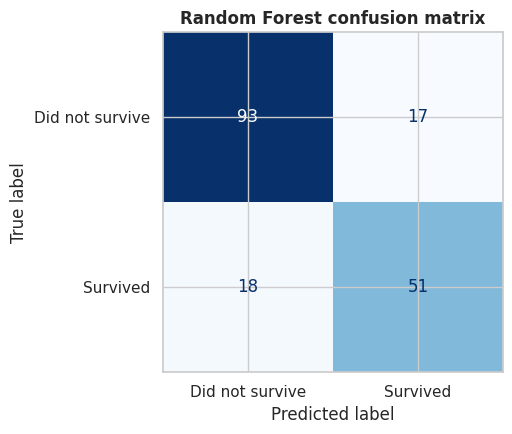

In [17]:
rf_pipeline = fitted_models['Random Forest']
rf_pred = rf_pipeline.predict(X_test)
rf_prob = rf_pipeline.predict_proba(X_test)[:, 1]
rf_metrics = {
    'Accuracy': accuracy_score(y_test, rf_pred),
    'Balanced accuracy': balanced_accuracy_score(y_test, rf_pred),
    'Precision (survived)': precision_score(y_test, rf_pred, zero_division=0),
    'Recall (survived)': recall_score(y_test, rf_pred, zero_division=0),
    'F1 (survived)': f1_score(y_test, rf_pred, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, rf_prob)
}
display(pd.DataFrame({'Metric': rf_metrics.keys(), 'Value': rf_metrics.values()}).style.format({'Value': '{:.4f}'}).hide(axis='index'))
print('Classification report:')
print(classification_report(y_test, rf_pred, target_names=['Did not survive', 'Survived'], zero_division=0))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, rf_pred, display_labels=['Did not survive', 'Survived'],
    cmap='Blues', values_format='d', ax=ax, colorbar=False
)
ax.set_title('Random Forest confusion matrix')
plt.tight_layout()
plt.show()

## 18. Random Forest permutation importance

Permutation importance measures how much the fitted model’s test accuracy changes when one original feature is shuffled. Near-zero or negative values can happen with overlapping predictors and sampling noise; they do not prove a feature is useless.

,Feature,Importance mean,Importance std
1,Sex,0.1028,0.0266
7,Title,0.0712,0.0193
2,Age,0.0455,0.0176
5,Fare,0.0307,0.0158
0,Pclass,0.0288,0.0133
8,FamilySize,0.0081,0.0096
6,Embarked,0.0045,0.0155
4,Parch,0.0031,0.0054
10,HasCabin,0.0000,0.0147
3,SibSp,-0.0020,0.0105


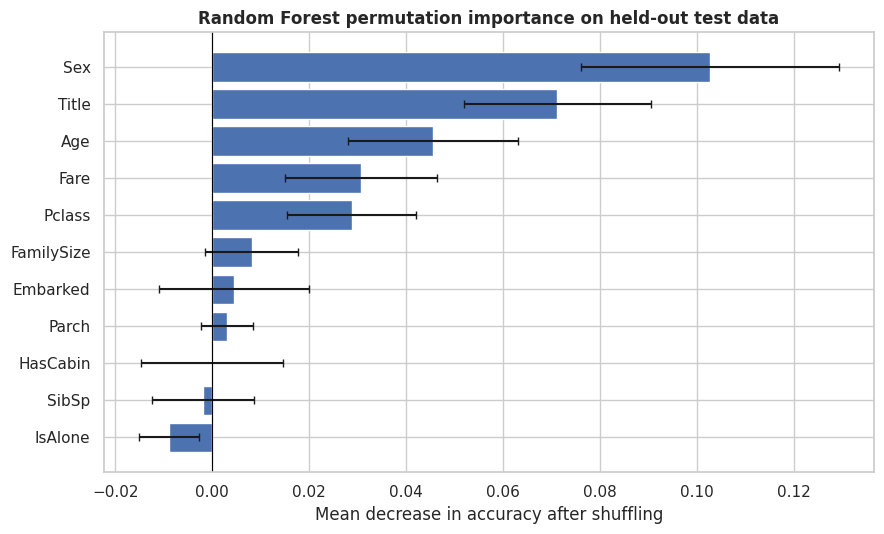

In [18]:
perm = permutation_importance(
    rf_pipeline, X_test, y_test,
    scoring='accuracy', n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1
)
importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance mean': perm.importances_mean,
    'Importance std': perm.importances_std
}).sort_values('Importance mean', ascending=False)
display(importance_df.round(4))

fig, ax = plt.subplots(figsize=(9, 5.5))
plot_importance = importance_df.sort_values('Importance mean')
ax.barh(plot_importance['Feature'], plot_importance['Importance mean'],
       xerr=plot_importance['Importance std'], capsize=3)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Random Forest permutation importance on held-out test data')
ax.set_xlabel('Mean decrease in accuracy after shuffling')
plt.tight_layout()
plt.show()

## 19. Mean/mode imputation and export of a clean analysis dataset

The exported CSV is a convenient fully imputed dataset for exploration and demonstrations. Here the observed `Age` mean and `Embarked` mode are calculated from the full dataset so the exported file has no missing values. **For predictive evaluation, do not fit models on this exported full-data-imputed file**; use the train-only pipelines above to avoid leakage.

In [19]:
clean_df = df[FEATURES + [TARGET]].copy()
age_mean = clean_df['Age'].mean()
embarked_mode = clean_df['Embarked'].mode(dropna=True).iloc[0]
clean_df['Age'] = clean_df['Age'].fillna(age_mean)
clean_df['Embarked'] = clean_df['Embarked'].fillna(embarked_mode)
# Defensive completion if another selected field ever contains missing values:
for col in NUMERIC_FEATURES:
    clean_df[col] = clean_df[col].fillna(clean_df[col].mean())
for col in CATEGORICAL_FEATURES:
    clean_df[col] = clean_df[col].fillna(clean_df[col].mode(dropna=True).iloc[0])

export_path = Path('titanic_cleaned_imputed.csv')
clean_df.to_csv(export_path, index=False)
print(f'Age mean used for export: {age_mean:.4f}')
print(f'Embarked mode used for export: {embarked_mode}')
print(f'Exported: {export_path.resolve()}')
print('Cleaned dataset shape:', clean_df.shape)
print('Remaining missing cells:', int(clean_df.isna().sum().sum()))
display(clean_df.head())

Age mean used for export: 29.6991
Embarked mode used for export: S
Exported: /mnt/data/titanic_cleaned_imputed.csv
Cleaned dataset shape: (891, 12)
Remaining missing cells: 0


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,FamilySize,IsAlone,HasCabin,Survived
0,3,male,22.0,1,0,7.2500,S,Mr,2,0,0,0
1,1,female,38.0,1,0,71.2833,C,Mrs,2,0,1,1
2,3,female,26.0,0,0,7.9250,S,Miss,1,1,0,1
3,1,female,35.0,1,0,53.1000,S,Mrs,2,0,1,1
4,3,male,35.0,0,0,8.0500,S,Mr,1,1,0,0


## 20. Findings and interpretation

In [20]:
majority_rate = y_train.value_counts(normalize=True).max()
best_test_row = metrics_df.iloc[0]
rf_row = metrics_df.loc[metrics_df['Model'] == 'Random Forest'].iloc[0]
best_cv_row = metrics_df.loc[metrics_df['CV accuracy mean'].idxmax()]

print(f"- Dataset: {len(df):,} passengers and {raw_df.shape[1]} original columns.")
print(f"- Target balance: {(df['Survived'] == 1).mean():.1%} survived and {(df['Survived'] == 0).mean():.1%} did not survive.")
print(f"- Original missing cells: {int(raw_df.isna().sum().sum())}; most missing values are in Cabin and Age.")
print(f"- Random Forest held-out accuracy: {rf_row['Test accuracy']:.2%}; mean 5-fold CV accuracy: {rf_row['CV accuracy mean']:.2%}.")
print(f"- Best held-out accuracy in this run: {best_test_row['Model']} ({best_test_row['Test accuracy']:.2%}).")
print(f"- Best mean CV accuracy in this run: {best_cv_row['Model']} ({best_cv_row['CV accuracy mean']:.2%}).")
print('- Sex and Title show strong descriptive associations with survival, but these associations are not causal explanations.')
print('- A single 80/20 test split can fluctuate. Use repeated cross-validation and tune hyperparameters before making strong model-selection claims.')

- Dataset: 891 passengers and 12 original columns.
- Target balance: 38.4% survived and 61.6% did not survive.
- Original missing cells: 866; most missing values are in Cabin and Age.
- Random Forest held-out accuracy: 80.45%; mean 5-fold CV accuracy: 81.89%.
- Best held-out accuracy in this run: Logistic Regression (83.24%).
- Best mean CV accuracy in this run: Logistic Regression (82.45%).
- Sex and Title show strong descriptive associations with survival, but these associations are not causal explanations.
- A single 80/20 test split can fluctuate. Use repeated cross-validation and tune hyperparameters before making strong model-selection claims.


## 21. Caveats and suggested next steps

- The dataset has 891 rows, so test metrics can vary with the split.
- The split and CV are stratified, and preprocessing is fit inside each pipeline to limit leakage.
- Mean imputation is simple and interpretable, but median imputation or explicit missingness indicators may be worth comparing.
- A small benchmark is not an exhaustive hyperparameter search.
- Correlations, group survival rates, and permutation importance are descriptive. They should not be interpreted as causal effects.
- For a stronger experiment, compare repeated stratified CV, tune model parameters using only the training portion, and evaluate the selected model once on the untouched test portion.

### End of notebook